Phase 2 : EXPLORATORY DATA ANALYSIS

#Objective
The objective of this phase is to explore the IndiaKart dataset visually to uncover trends, patterns,
and relationships in orders, revenue, customers, and products. 
Each chart is accompanied by a short observation to support business insights in later phases.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

orders = pd.read_csv("Data/orders DA.csv")
order_items = pd.read_csv("Data/order_items DA.csv")
customers = pd.read_csv("Data/customers DA.csv")
inventory = pd.read_csv("Data/inventory DA.csv")
payments = pd.read_csv("Data/payments DA.csv")
products = pd.read_csv("Data/products DA.csv")
suppliers = pd.read_csv("Data/suppliers DA.csv")
returns = pd.read_csv("Data/returns DA.csv")

In [6]:
#Check Order status
print("order status")
print(orders["status"].value_counts())

order status
Delivered     32499
Cancelled      5996
Shipped        5071
Returned       3933
Processing     2501
Name: status, dtype: int64


In [7]:
#check order channels
print("order channels")
print(orders["channel"].value_counts())

order channels
App           27549
Website       14820
Mobile Web     7631
Name: channel, dtype: int64


In [8]:
#check payment methods
print("payment methods")
print(orders["payment_method"].value_counts())

payment methods
UPI                 17570
Credit Card         10007
Debit Card           7624
Cash on Delivery     5883
Net Banking          4026
EMI                  2943
Wallet               1947
Name: payment_method, dtype: int64


#chart 1 :Monthly Order Volume

In [12]:
orders['order_date']=pd.to_datetime(orders['order_date'],errors='coerce')

C:\Users\User\AppData\Local\Temp\ipykernel_25204\401751724.py:1: UserWarning: Parsing dates in DD/MM/YYYY format when dayfirst=False (the default) was specified. This may lead to inconsistently parsed dates! Specify a format to ensure consistent parsing.
  orders['order_date']=pd.to_datetime(orders['order_date'],errors='coerce')


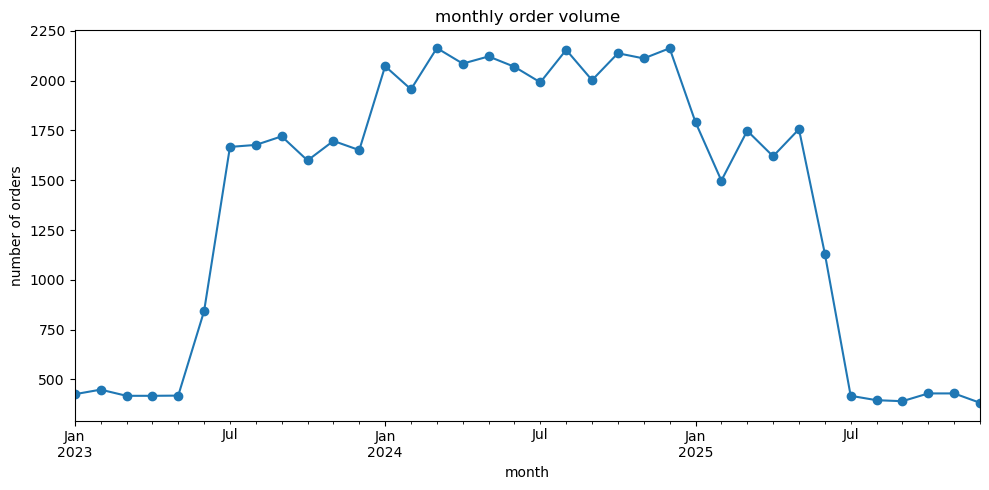

In [13]:
orders['order_month']= orders['order_date'].dt.to_period('M')
monthly_orders = orders.groupby('order_month').size()
plt.figure(figsize=(10,5))
monthly_orders.plot(kind= 'line',marker='o')
plt.title('monthly order volume')
plt.xlabel('month')
plt.ylabel('number of orders')
plt.tight_layout()
plt.show()

#Chart 2 : Monthly GMV (Revenue)
#SUM final_amount per month to track total revenu (gross merchandise value) trends alongside order volumne 


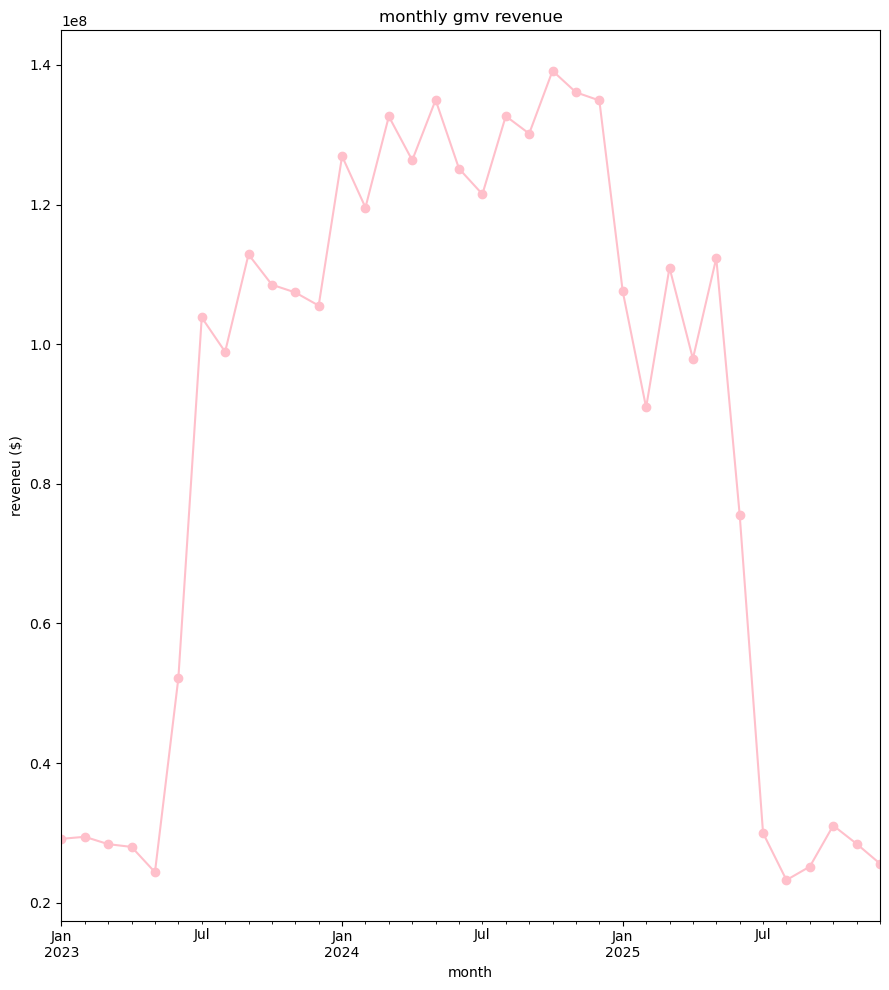

In [17]:
monthly_gmv = orders.groupby('order_month')['final_amount'].sum()

plt.figure(figsize=(9,10))
monthly_gmv.plot(kind='line',marker='o',color='pink')
plt.title('monthly gmv revenue')
plt.xlabel('month')
plt.ylabel('reveneu ($)')
plt.tight_layout()
plt.show()

In [18]:
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")

print("Start date:", orders["order_date"].min())
print("End date:", orders["order_date"].max())

monthly_revenue = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["final_amount"].sum()

print(monthly_revenue)

Start date: 2023-01-07 00:00:00
End date: 2025-12-06 00:00:00
order_date
2023-01    2.915500e+07
2023-02    2.944705e+07
2023-03    2.839437e+07
2023-04    2.799788e+07
2023-05    2.437563e+07
2023-06    5.214389e+07
2023-07    1.038245e+08
2023-08    9.890524e+07
2023-09    1.128542e+08
2023-10    1.085170e+08
2023-11    1.074071e+08
2023-12    1.055257e+08
2024-01    1.269281e+08
2024-02    1.195743e+08
2024-03    1.326217e+08
2024-04    1.263413e+08
2024-05    1.349753e+08
2024-06    1.251430e+08
2024-07    1.214803e+08
2024-08    1.326699e+08
2024-09    1.301557e+08
2024-10    1.391548e+08
2024-11    1.360710e+08
2024-12    1.349085e+08
2025-01    1.075683e+08
2025-02    9.093828e+07
2025-03    1.109671e+08
2025-04    9.791327e+07
2025-05    1.123339e+08
2025-06    7.558189e+07
2025-07    2.998051e+07
2025-08    2.325067e+07
2025-09    2.518154e+07
2025-10    3.105866e+07
2025-11    2.844129e+07
2025-12    2.559860e+07
Freq: M, Name: final_amount, dtype: float64


In [19]:
monthly_orders = orders.groupby(
    orders["order_date"].dt.to_period("M")
).size()

print(monthly_orders)

order_date
2023-01     426
2023-02     449
2023-03     418
2023-04     418
2023-05     419
2023-06     843
2023-07    1667
2023-08    1677
2023-09    1720
2023-10    1599
2023-11    1697
2023-12    1651
2024-01    2072
2024-02    1956
2024-03    2163
2024-04    2085
2024-05    2121
2024-06    2069
2024-07    1991
2024-08    2154
2024-09    2002
2024-10    2137
2024-11    2111
2024-12    2162
2025-01    1791
2025-02    1498
2025-03    1748
2025-04    1620
2025-05    1756
2025-06    1132
2025-07     418
2025-08     396
2025-09     391
2025-10     430
2025-11     430
2025-12     383
Freq: M, dtype: int64


In [20]:
print(orders.groupby(orders["order_date"].dt.year).size())

print("\nOrders by year and status:")
print(pd.crosstab(
    orders["order_date"].dt.year,
    orders["status"]
))

order_date
2023    12984
2024    25023
2025    11993
dtype: int64

Orders by year and status:
status      Cancelled  Delivered  Processing  Returned  Shipped
order_date                                                     
2023             1524       8420         661      1075     1304
2024             3027      16315        1219      1953     2509
2025             1445       7764         621       905     1258


In [21]:
print(
    orders.groupby(
        orders["order_date"].dt.to_period("M")
    )["final_amount"].agg(["count", "sum", "mean"]).tail(12)
)

            count           sum          mean
order_date                                   
2025-01      1791  1.075683e+08  60060.474394
2025-02      1498  9.093828e+07  60706.462931
2025-03      1748  1.109671e+08  63482.334130
2025-04      1620  9.791327e+07  60440.287846
2025-05      1756  1.123339e+08  63971.487198
2025-06      1132  7.558189e+07  66768.454629
2025-07       418  2.998051e+07  71723.704211
2025-08       396  2.325067e+07  58713.816490
2025-09       391  2.518154e+07  64402.927980
2025-10       430  3.105866e+07  72229.432326
2025-11       430  2.844129e+07  66142.529488
2025-12       383  2.559860e+07  66837.073864


# Key insights from the data
KPI	Month	Value
Highest order count	January 2025	1,791
Highest monthly revenue	May 2025	₹11.23 crore
Highest average order value	October 2025	₹72,229.43
Lowest order count	December 2025	383
Lowest monthly revenue	August 2025	₹2.33 crore
Lowest average order value	August 2025	₹58,713.82

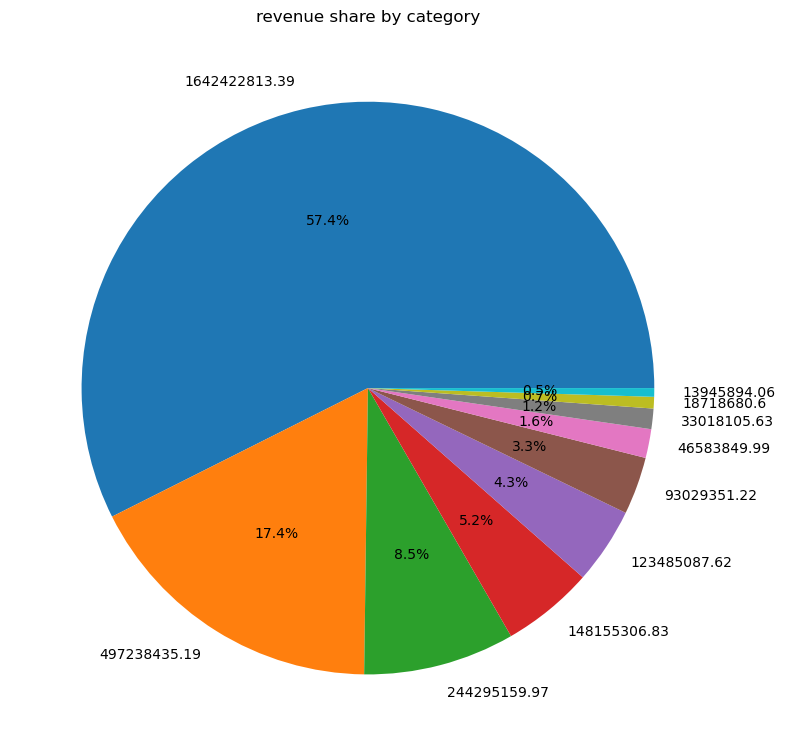

In [23]:
# chart3 revenue share by categroy
category_revenue = order_items.groupby('category')['total_price'].sum().sort_values(ascending = False)
plt.figure(figsize=(8,8))
plt.pie(category_revenue , labels = category_revenue , autopct ='%1.1f%%')
plt.title('revenue share by category')
plt.tight_layout()
plt.show()

In [24]:
# chart 4 order status breakdown

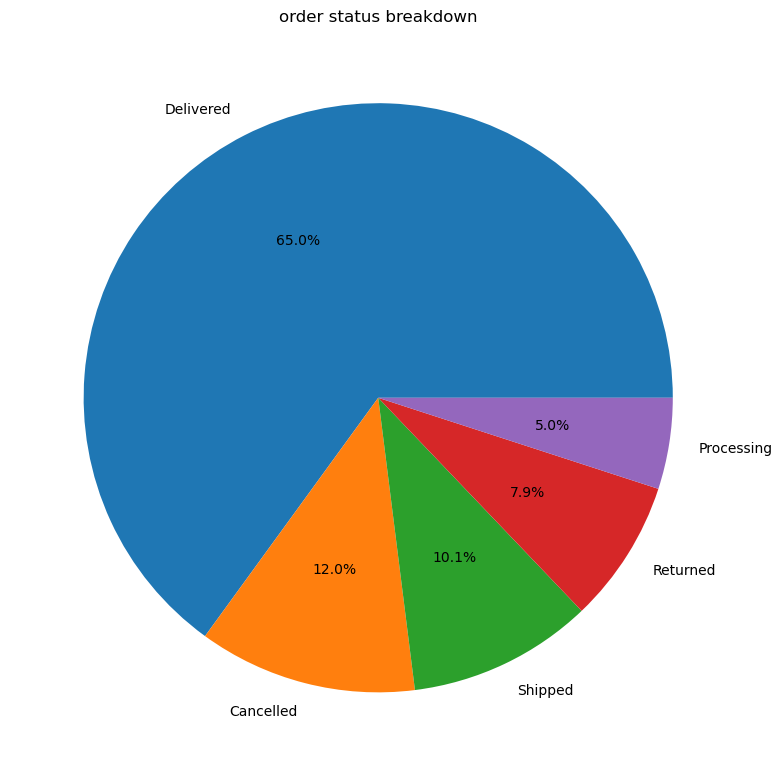

In [26]:
status_counts = orders['status'].value_counts()
plt.figure(figsize=(8,9))
plt.pie(status_counts,labels=status_counts.index,autopct='%1.1f%%')
plt.title("order status breakdown")
plt.tight_layout()
plt.show()

In [28]:
#chart 5 : top 10 states by customer count

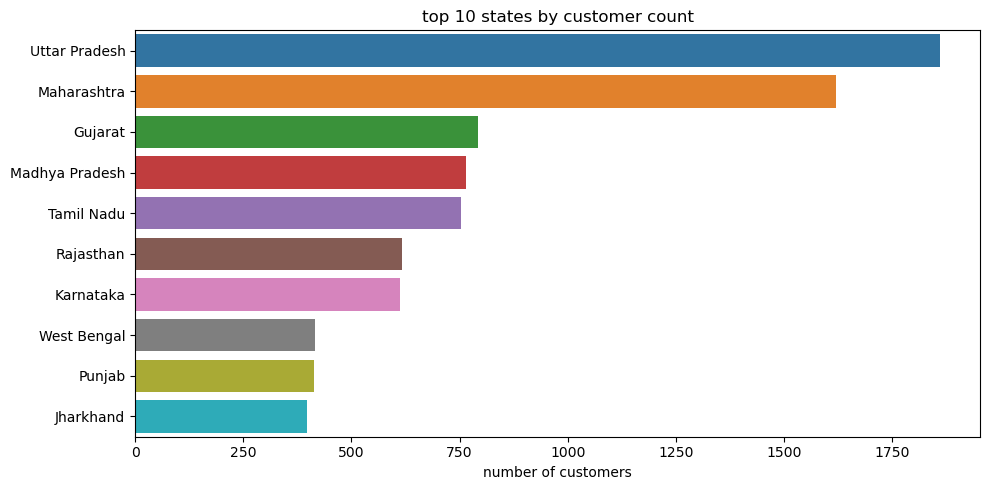

In [31]:
import seaborn as sns
top_states = customers['state'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_states.values,y=top_states.index)
plt.title("top 10 states by customer count")
plt.xlabel("number of customers")
plt.tight_layout()
plt.show()


In [32]:
#chart 6 customer segment dristribution

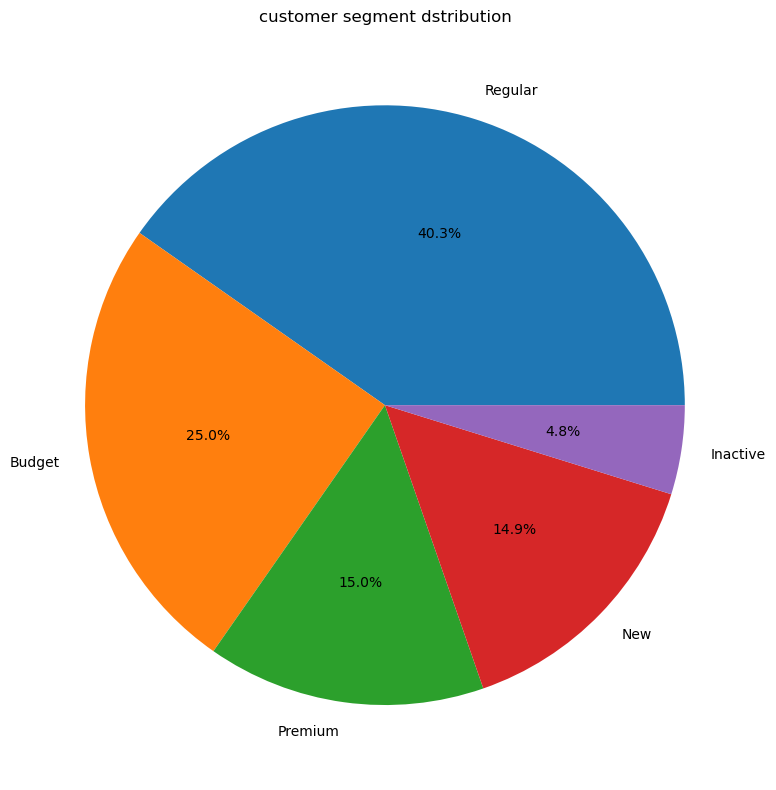

In [34]:
segment_counts =customers['segment'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(segment_counts,labels= segment_counts.index,autopct='%1.1f%%')
plt.title('customer segment dstribution')
plt.tight_layout()
plt.show()

In [35]:
#chart 7 payment method usage

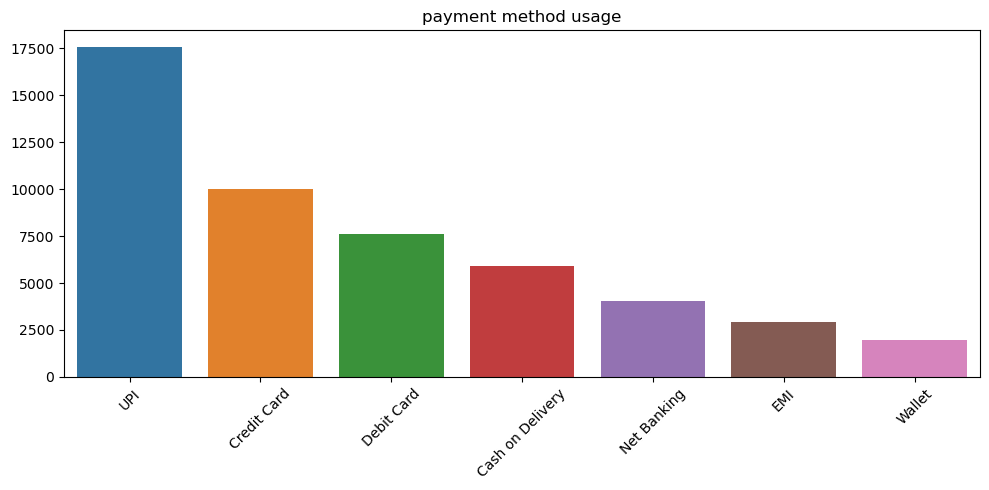

In [38]:
payment_counts = orders['payment_method'].value_counts()
plt.figure(figsize=(10,5))
sns.barplot(x=payment_counts.index,y=payment_counts.values)
plt.title('payment method usage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
#chart 8 customer age distribution

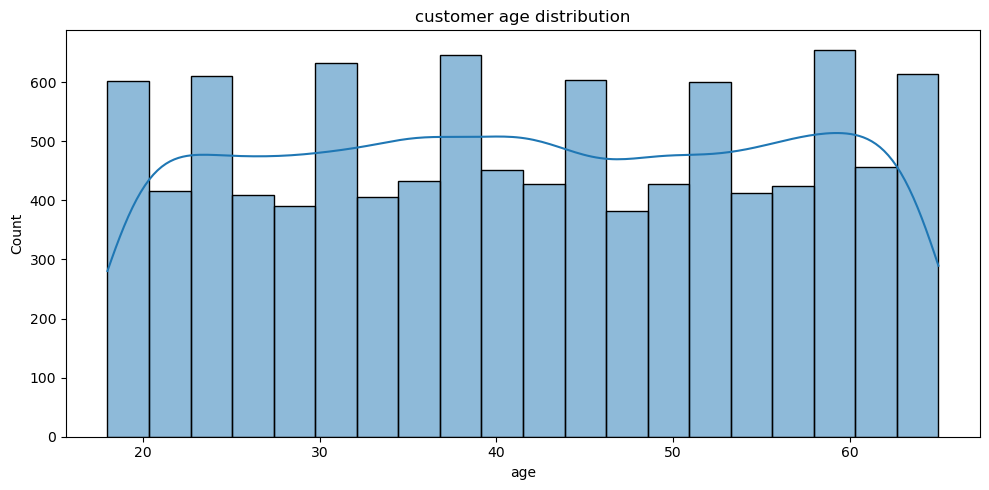

In [40]:
plt.figure(figsize=(10,5))
sns.histplot(customers['age'],bins=20,kde=True)
plt.title('customer age distribution')
plt.xlabel('age')
plt.tight_layout()
plt.show()

In [41]:
#chat 9 return reason

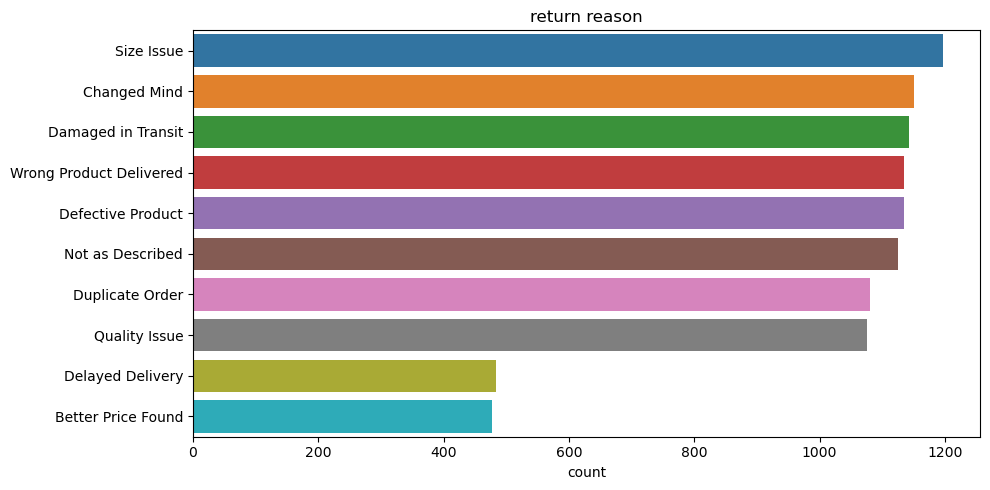

In [43]:
return_reasons = returns['reason'].value_counts()
plt.figure(figsize=(10,5))
sns.barplot(x=return_reasons.values,y=return_reasons.index)
plt.title('return reason')
plt.xlabel('count')
plt.tight_layout()
plt.show()

In [44]:
#chart 10 average order value (AOV) by customer segment

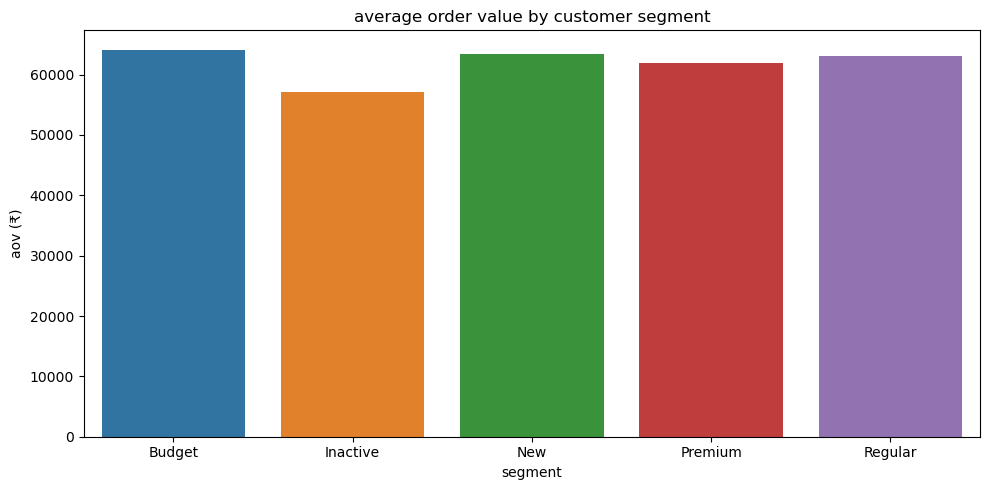

In [47]:
orders_seg = orders.merge(customers[['customer_id','segment']],on='customer_id',how='left')
aov_by_segment = orders_seg.groupby('segment')['final_amount'].mean()
plt.figure(figsize=(10,5))
sns.barplot(x=aov_by_segment.index,y=aov_by_segment.values)
plt.title('average order value by customer segment')
plt.ylabel('aov (₹)')
plt.tight_layout()
plt.show()

The EDA revealed that IndiaKart's business is concentrated, not evenly spread, across several dimensions:

1. Orders & Revenue: Monthly order volume and GMV move together, with peaks around seasonal sales.
2. Category: A small number of categories drive most of the revenue.
3. Order Status: Most orders are successfully Delivered; Cancelled/Returned orders are a minority.
4. Geography: Customers are concentrated in a handful of top states.
5. Segment: One customer segment makes up the largest share of the customer base.
6. Payments: One or two payment methods dominate transaction volume.
7. Age: Customers cluster around a specific age range.
8. Returns: A few return reasons account for most returns.
9. AOV: Average order value varies noticeably by customer segment